<a href="https://colab.research.google.com/github/gasmibillel97-ctrl/IDS-research-younes/blob/main/Proposed_NCA_BKNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

import libraries

In [4]:
# we import all the libraries we need for this paper
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import RFECV
from sklearn.model_selection import KFold,StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, classification_report, auc, roc_curve
from sklearn.pipeline import Pipeline
from sklearn.ensemble import BaggingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import NeighborhoodComponentsAnalysis
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt
import time # Import the time module
import warnings
warnings.filterwarnings("ignore")

 Distribution of samples across all 15 datasets (see Fig. 4).

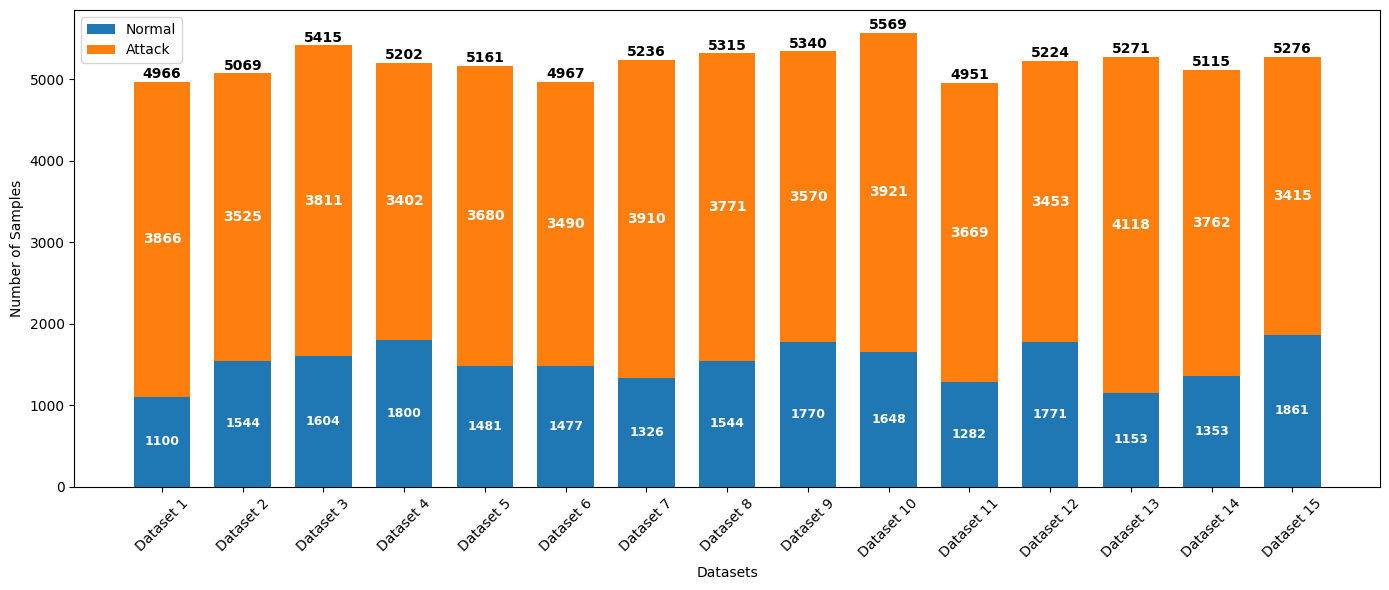

In [22]:
# Dataset names
datasets = ["Dataset 1", "Dataset 2", "Dataset 3", "Dataset 4", "Dataset 5",
    "Dataset 6", "Dataset 7", "Dataset 8", "Dataset 9", "Dataset 10",
    "Dataset 11", "Dataset 12", "Dataset 13", "Dataset 14", "Dataset 15" ]

# Binary class counts
Normal = np.array([1100, 1544, 1604, 1800, 1481, 1477,1326, 1544, 1770, 1648, 1282, 1771, 1153, 1353, 1861])
Attack = np.array([3866,  3525,  3811, 3402,3680, 3490,  3910,  3771, 3570, 3921,  3669,  3453,  4118, 3762, 3415])

x = np.arange(len(datasets))

plt.figure(figsize=(14, 6))

# Stacked bars
plt.bar(x, Normal, width=0.7, label="Normal")
plt.bar(x, Attack, bottom=Normal, width=0.7, label="Attack")

# we plot labels inside bars and we put total on top each bar
for i in range(len(x)):
    total = Normal[i] + Attack[i]

    # Class 0 (normal) label (inside)
    plt.text(
        x[i],
        Normal[i] / 2,
        str(Normal[i]),
        ha="center",
        va="center",
        color="white",
        fontsize=9,
        fontweight="bold"
    )

    # Class 1 (attack )label (inside)
    plt.text(
        x[i],
        Normal[i] + Attack[i] / 2,
        str(Attack[i]),
        ha="center",
        va="center",
        color="white",
        fontsize=10,
        fontweight="bold"
    )

    # we put total label above bar
    plt.text(
        x[i],
        total + 8,
        str(total),
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

# plotting
plt.xticks(x, datasets, rotation=45)
plt.ylabel("Number of Samples")
plt.xlabel("Datasets")
plt.legend()
plt.grid(axis="y", alpha=0.0)
plt.tight_layout()
# save the figure
plt.savefig("binary_class_distribution.svg", dpi=500, bbox_inches="tight")
plt.show()

import the datasets



In [23]:
# we load the 15 datasets for binary and multiclass classification (umpoad from this link: https://sites.google.com/a/uah.edu/tommy-morris-uah/ics-data-sets)
# from data1 to  data15
df=pd.read_csv('/content/drive/MyDrive/binaryAllNaturalPlusNormalVsAttacks-20250413T111634Z-001.csv/binaryAllNaturalPlusNormalVsAttacks/data1.csv')

In [24]:
# we show the desribution and shape of each data
df.head()
df.shape

(4966, 129)

data preprocessing ( mapping, cleansing, Normalization)

In [25]:
# mapping normal and attack classes
df['marker'] = df['marker'].map({'Natural': 0, 'Attack': 1})

In [26]:
# during data preprocessing, we remove the +- infinity values using downsampling technique, then we seperate the features from class, the features were then sclled using MinMaxScaler class
# remove +- infinity values
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna()
# separation the data
X = df.drop('marker', axis=1)
y = df['marker']
# Normalization the data
scaler = MinMaxScaler()
# Scale the entire DataFrame
X_scaled=scaler.fit_transform(X)
X_scaled=pd.DataFrame(X_scaled,columns=X.columns)
y.value_counts()

,count
marker,
1,3610
0,1008


dataset splitting into training and testing sets ( 90% for training and 10% for testing)




In [27]:
# we randomly split the dataset into training and testing sets (90% for training and the remaining 10% for testing) and then we use the training set
# for feature selection ()
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.1, random_state=1)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((4156, 128), (462, 128), (4156,), (462,))

Feature selection using RFECV





In [18]:
# here we apply recursive feature elimination feature selection technique to select the best features, this technique
# automatically select these features without needing to determint how much the features to keep
rfecv= RFECV(estimator=RandomForestClassifier(random_state=42,n_estimators=500,criterion='gini'),step=5, cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=42), scoring='accuracy',min_features_to_select=10, n_jobs=-1)
rfecv.fit(X_train,y_train)

Displaying the number and type of the  selected features

In [ ]:
print(f"Optimal number of features: {rfecv.n_features_}")
print(f"Optimal features: {list(rfecv.get_feature_names_out())}")

Separating the selected features from the orignal dataset**


In [ ]:
X_selected=  ['R1-PA1:VH', 'R1-PA2:VH', 'R1-PM2:V', 'R1-PA3:VH', 'R1-PM4:I', 'R1-PA5:IH', 'R1-PM5:I', 'R1-PM6:I', 'R1-PA7:VH', 'R1-PA10:IH', 'R1-PM10:I', 'R2-PA1:VH', 'R2-PM1:V', 'R2-PA2:VH', 'R2-PM2:V', 'R2-PA3:VH', 'R2-PM3:V', 'R2-PA4:IH', 'R2-PA5:IH', 'R2-PM5:I', 'R2-PA6:IH', 'R2-PA7:VH', 'R2-PM7:V', 'R2-PA10:IH', 'R2-PM10:I', 'R2-PA:Z', 'R3-PA1:VH', 'R3-PA2:VH', 'R3-PM2:V', 'R3-PA3:VH', 'R3-PA4:IH', 'R3-PM4:I', 'R3-PA5:IH', 'R3-PM5:I', 'R3-PA6:IH', 'R3-PM6:I', 'R3-PA7:VH', 'R3-PA10:IH', 'R3-PM10:I', 'R4-PA1:VH', 'R4-PM1:V', 'R4-PA2:VH', 'R4-PM2:V', 'R4-PA3:VH', 'R4-PM3:V', 'R4-PA4:IH', 'R4-PM4:I', 'R4-PA5:IH', 'R4-PM5:I', 'R4-PM6:I', 'R4-PA7:VH', 'R4-PM7:V', 'R4-PM10:I']

Return the reduced features from the original features


In [ ]:
X_train_selected = X_train[X_selected]
X_test_selected = X_test[X_selected]
# print (X_train_selected .shape)
# print (X_test_selected.shape)

Evaluation the proposed BKNN on the original 128 features and on the top selected features ( binary and multiclass events)

In [29]:
# Define the base estimator (KNN)
knn = KNeighborsClassifier(metric= 'euclidean',n_neighbors=1)
# Define the Bagging Classifier
bagging_knn = BaggingClassifier(estimator=knn, random_state=1)

# Fit the Bagging KNN model and measure training time
start_time = time.time()
# bagging_knn.fit(X_train, y_train)        # Fitting model to the original 128 features
bagging_knn.fit(X_train, y_train)   # Fitting model to the top selected features
training_time = time.time() - start_time

# Make predictions and measure testing time
start_time = time.time()
# y_pred_bknn = bagging_knn.predict(X_test)   # evaluation on the original 128 features
y_pred_bknn = bagging_knn.predict(X_test) # evaluation on the top selected features
testing_time = time.time() - start_time

# Evaluate the Bagging KNN model
accuracy = accuracy_score(y_test, y_pred_bknn)
precision = precision_score(y_test, y_pred_bknn, average="binary") # we use average="weighted" for multiclass datasets
recall = recall_score(y_test, y_pred_bknn, average="binary")
f1 = f1_score(y_test, y_pred_bknn,average="binary")
# confusion matrix
cm = confusion_matrix(y_test, y_pred_bknn)

# print values of each metric
# print(f"Bagging KNN Accuracy: {accuracy:.4f}")
print(f"Bagging KNN Precision: {precision:.4f}")
print(f"Bagging KNN Recall: {recall:.4f}")
print(f"Bagging KNN F1-score: {f1:.4f}")
print("\nConfusion Matrix:")
print(cm)                # we use confusion matrix to calculate the FPR/FNR ...
# print training and testing time
print(f"Bagging KNN Training Time: {training_time:.4f} seconds")
print(f"Bagging KNN Testing Time: {testing_time:.4f} seconds")

As the scond stage for feature selection, NCA technique is used to maximize the distance between different classess and hence we boost the BKNN to detect the events more accurately



NCA Components: 1, Bagging KNN Accuracy: 0.7554585152838428
NCA Components: 2, Bagging KNN Accuracy: 0.9781659388646288
NCA Components: 3, Bagging KNN Accuracy: 0.980349344978166
NCA Components: 4, Bagging KNN Accuracy: 0.9759825327510917
NCA Components: 5, Bagging KNN Accuracy: 0.9694323144104804
NCA Components: 6, Bagging KNN Accuracy: 0.9716157205240175
NCA Components: 7, Bagging KNN Accuracy: 0.9716157205240175
NCA Components: 8, Bagging KNN Accuracy: 0.9716157205240175
NCA Components: 9, Bagging KNN Accuracy: 0.9759825327510917
NCA Components: 10, Bagging KNN Accuracy: 0.9694323144104804


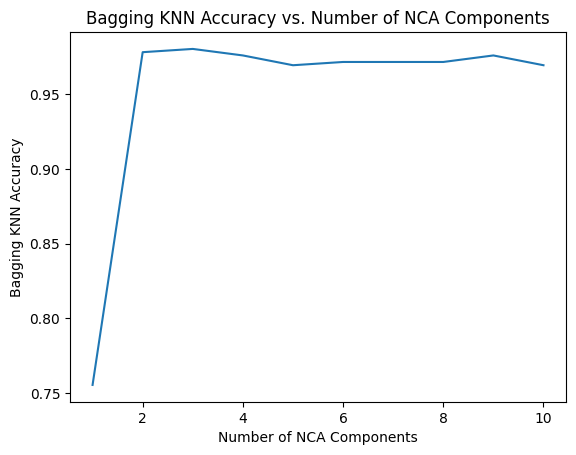

In [ ]:
from sklearn.neighbors import NeighborhoodComponentsAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import BaggingClassifier
import matplotlib as plt
from xgboost import XGBClassifier
import matplotlib.pyplot as plt

n_features_selected = X_train_selected.shape[1]
accuracies = []

knn=KNeighborsClassifier(metric='euclidean',n_neighbors=1)
for n_components in range(1, n_features_selected + 1):
    # Apply NCA
    nca = NeighborhoodComponentsAnalysis(n_components=n_components, random_state=42)
    X_train_nca = nca.fit_transform(X_train_selected, y_train)
    X_test_nca = nca.transform(X_test_selected)

    # Define the Bagging Classifier with KNN as base estimator
    bagging_knn = BaggingClassifier(estimator=knn, random_state=42,n_jobs=-1,n_estimators=30) # Define BaggingClassifier

    # Fit the ensemble model
    bagging_knn.fit(X_train_nca, y_train) # Fit BaggingClassifier

    # Make predictions
    bagging_predictions = bagging_knn.predict(X_test_nca) # Predict using BaggingClassifier

    # Evaluate the ensemble model
    accuracy = accuracy_score(y_test, bagging_predictions)
    accuracies.append(accuracy)
    print(f"NCA Components: {n_components}, Bagging KNN Accuracy: {accuracy}") # Update print statement

# Plot the accuracies
plt.plot(range(1, n_features_selected + 1), accuracies)
plt.xlabel("Number of NCA Components")
plt.ylabel("Bagging KNN Accuracy") # Update plot label
plt.title("Bagging KNN Accuracy vs. Number of NCA Components") # Update plot title
plt.show()

We plot the figure that reprsent the BKNN accuracy across different number of components (see figure 5)

In [ ]:
# we plot the figure that reprsent the BKNN accuracy across different number of components.
# code for figure 5

# Iteratevly find best accuracy
best_idx        = int(np.argmax(accuracies))          # index (0-based)
best_n          = best_idx + 1                         # n_components (1-based)
best_acc        = accuracies[best_idx]
x_range         = range(1, n_features_sel + 1)


fig, ax = plt.subplots(figsize=(9, 6))

# accuracy curve
ax.plot(x_range, accuracies,
        color='blue', marker='o', markersize=4,
        linewidth=1.5, label='Accuracy Curve', zorder=3)

# best point with red dot + annotation
ax.scatter(best_n, best_acc,
           color='red', s=80, zorder=5)
ax.annotate(f'({best_n}, {best_acc:.4f})',
            xy=(best_n, best_acc),
            xytext=(best_n + 1.5, best_acc - 0.003),
            fontsize=9, color='red',
            arrowprops=dict(arrowstyle='->', color='red', lw=1.2))

# vertical dashed line that best n_component
ax.axvline(x=best_n, color='black', linestyle='--', linewidth=1.2,
           label=f'Best n_components={best_n}')

# Horizontal dashed line at best acuraccy
ax.axhline(y=best_acc, color='gray', linestyle='--', linewidth=1.2,
           label=f'Max BKNN Acc={best_acc:.4f}')

# PLOtting
ax.set_xlabel('Number of NCA Components', fontsize=11)
ax.set_ylabel('Bagging KNN Accuracy',     fontsize=11)
ax.set_xlim(0, n_features_sel + 1)
ax.set_ylim(min(accuracies) - 0.05, 1.01)

ax.legend(loc='lower right', fontsize=9, framealpha=0.9)
ax.grid(True, linestyle='--', alpha=0.4)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig("BKNN_Accuracy_vs_NCA.svg", dpi=300, bbox_inches='tight')
plt.show()

print(f"\nBest n_components : {best_n}")
print(f"Best Accuracy     : {best_acc:.4f}")

Using the top selected features ( n_components) to validate the BKNN using different evaluation metrics

In [ ]:
# Here, we evaluate the the proposed BKNN model on n_components using different metrics

n_components =3 # the best selected components after using NCA
nca = NeighborhoodComponentsAnalysis(n_components=n_components,random_state=42)

X_train_nca = nca.fit_transform(X_train, y_train)
X_test_nca = nca.transform(X_test)


knn = KNeighborsClassifier(metric='euclidean',n_neighbors=1)
bagging_knn = BaggingClassifier(estimator=knn, random_state=42,n_estimators=50)

# Fit the Bagging KNN model on the training data and measure training time
start_time = time.time()
bagging_knn .fit(X_train_nca, y_train)
training_time = time.time() - start_time

# Make predictions and measure testing time
start_time = time.time()
y_pred_bknn = bagging_knn .predict(X_test_nca)
testing_time = time.time() - start_time

# Evaluate the Bagging KNN model on the test set
accuracy = accuracy_score(y_test, y_pred_bknn)
precision = precision_score(y_test, y_pred_bknn, average="binary") # we use average="weighted" for multiclass datasets
recall = recall_score(y_test, y_pred_bknn, average="binary")
f1 = f1_score(y_test, y_pred_bknn, average="binary")

# confusion matrix
cm = confusion_matrix(y_test, y_pred_bknn)

# print values of each metric
print(f"Bagging KNN Accuracy: {accuracy:.4f}")
print(f"Bagging KNN Precision: {precision:.4f}")
print(f"Bagging KNN Recall: {recall:.4f}")
print(f"Bagging KNN F1-score: {f1:.4f}")
print("\nConfusion Matrix:")
print(cm)                # we use confusion matrix to calculate the FPR/FNR ...
# print training and testing time
print(f"Bagging KNN Training Time: {training_time:.4f} seconds")
print(f"Bagging KNN Testing Time: {testing_time:.4f} seconds")


Bagging KNN Accuracy (Test Set): 0.9803
Bagging KNN Precision (Test Set): 0.9863
Bagging KNN Recall (Test Set): 0.9830
Bagging KNN F1-score (Test Set): 0.9847
Bagging KNN Training Time: 0.4750 seconds
Bagging KNN Testing Time: 0.1260 seconds


In [ ]:
# 3D Plot of Selected Features (NCA Components)

Plot the Performance of the proposed approach on 15 binary and mulri class datasets using different metrics accuracy, precesion, recall, f1 (these results are important to show how the model improved effectively after each step)

In [ ]:
# Performance of the proposed approach on 15 binary class datasets for


datasets = np.arange(1, 16)
# accuracy
acc_original = [96.54, 95.10, 95.38, 96.03, 94.51, 93.67, 96.11, 99.11, 94.72, 94.11,
           94.19, 93.10, 95.69, 95.74, 95.06] # accuracy values before feature selection (128 features)

acc_rfecv = [98.48, 97.23, 99.20, 98.33, 95.99, 96.72, 97.51, 97.55, 95.93, 97.05,
             97.30, 96.86, 97.95, 98.30, 97.33] # accuracy values after feature selection using RFECV

acc_nca = [99.57, 98.93, 99.60, 99.16, 99.16, 98.69, 99.38, 99.18, 98.58, 99.02,
           99.38, 98.95, 99.18, 98.72, 98.77] # accuracy values after using NCA

plt.figure(figsize=(9,4.5))
plt.plot(datasets, acc_original, marker='D', linewidth=2, label='Original Features',color='blue')
plt.plot(datasets, acc_rfecv, marker='*', linewidth=2, markersize=9, label='RFECV',color='green')
plt.plot(datasets, acc_nca, marker='o', linewidth=2, label='RFECV-NCA',color='red')
plt.xlabel('Dataset')
plt.ylabel('Accuracy (%)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("binary class accuracy.svg", dpi=500, bbox_inches="tight")
plt.show()
# *******************************************************
# precision
prec_original = [96.94, 96.31, 96.82, 96.77, 95.68, 95.22, 97.57, 95.18, 95.50, 97.03,
            96.34, 93.63, 96.51, 96.53, 96.09]

prec_rfecv = [98.87, 98.14, 99.71, 99.02, 96.05, 97.94, 97.95, 97.70, 96.96, 98.66,
              98.04, 97.40, 98.12, 99.70, 98.04]

prec_nca = [99.43, 99.38, 100.00, 99.67, 99.38, 98.74, 99.45, 99.13, 98.20, 99.43,
            99.72, 99.07, 98.92, 99.41, 99.02]

plt.figure(figsize=(9,4.5))
plt.plot(datasets, prec_original, marker='D', linewidth=2, label='Original Features',color='blue')
plt.plot(datasets, prec_rfecv, marker='*', linewidth=2, markersize=9, label='RFECV',color='green')
plt.plot(datasets, prec_nca, marker='o', linewidth=2, label='RFECV-NCA',color='red')
plt.xlabel('Dataset')
plt.ylabel('Precision (%)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("binary class precision.svg", dpi=500, bbox_inches="tight")
plt.show()
# *******************************************************
# recall
rec_original = [98.59, 96.60, 96.54, 97.09, 96.27, 94.90, 96.54, 96.83, 96.66, 94.97,
           95.80, 95.77, 97.83, 97.66, 96.09]

rec_rfecv = [99.15, 97.84, 99.14, 98.38, 98.14, 96.94, 99.18, 98.84, 96.96, 97.35,
             98.32, 97.72, 99.18, 97.95, 97.72]

rec_nca = [100, 99.07, 99.42, 99.03, 99.38, 99.37, 99.73, 99.71, 99.70, 99.15,
           99.44, 99.38, 100.00, 98.83, 99.02]

plt.figure(figsize=(9,4.5))
plt.plot(datasets, rec_original, marker='D', linewidth=2, label='Original Features',color='blue')
plt.plot(datasets, rec_rfecv, marker='*', linewidth=2, markersize=9, label='RFECV',color='green')
plt.plot(datasets, rec_nca, marker='o', linewidth=2, label='RFECV-NCA',color='red')
plt.xlabel('Dataset')
plt.ylabel('Recall (%)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("binary class recall.svg", dpi=500, bbox_inches="tight")
plt.show()
# *******************************************************
# f1
f1_original = [97.76, 96.46, 96.68, 96.93, 95.98, 95.06, 97.24, 96.00, 96.07, 95.99,
          96.07, 94.69, 97.17, 97.09, 96.09]

f1_rfecv = [99.01, 98.00, 99.42, 98.70, 97.08, 97.44, 98.37, 98.27, 96.96, 98.00,
            98.18, 97.56, 98.65, 98.82, 97.88]

f1_nca = [99.72, 99.23, 99.71, 99.35, 99.38, 99.05, 99.59, 99.42, 98.94, 99.29,
          99.58, 99.22, 99.46, 99.12, 99.02]

plt.figure(figsize=(9,4.5))
plt.plot(datasets, f1_original, marker='D', linewidth=2, label='Original Features',color='blue')
plt.plot(datasets, f1_rfecv, marker='*', linewidth=2, markersize=9, label='RFECV',color='green')
plt.plot(datasets, f1_nca, marker='o', linewidth=2, label='RFECV-NCA',color='red')
plt.xlabel('Dataset')
plt.ylabel('F1-score (%)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("binary class f1.svg", dpi=500, bbox_inches="tight")
plt.show()

In [ ]:
# Performance of the proposed approach on 15 multi class datasets

# accuracy
import matplotlib.pyplot as plt
import numpy as np

datasets = np.arange(1, 16)

acc_original = [88.31, 87.21, 86.78, 88.91, 87.13,
              85.81, 88.17, 87.94, 87.60, 86.84,
              86.17, 84.52, 88.09, 85.53, 89.92]

rfecv_acc = [95.02, 92.96, 93.60, 95.19, 93.67,
             94.32, 95.64, 94.48, 91.87, 92.34,
             92.77, 92.89, 95.48, 93.62, 90.74]

nca_acc = [96.10, 97.01, 96.54, 97.49, 96.20,
           97.38, 97.93, 96.93, 96.14, 98.23,
           97.02, 96.03, 98.36, 95.32, 98.77]

plt.figure(figsize=(9, 4.5))
plt.plot(datasets, acc_original, marker='D', linewidth=2,label='Original Features',color='blue')
plt.plot(datasets, rfecv_acc, marker='*', linewidth=2, markersize=9, label='RFECV',color='green')
plt.plot(datasets, nca_acc, marker='o', linewidth=2, label='RFECV-NCA',color='red')

plt.xlabel('Dataset')
plt.ylabel('Accuracy (%)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("multi class accuracy.svg", dpi=500, bbox_inches="tight")
plt.show()

# *******************************************************
# precision
prec_original = [88.81, 88.18, 88.14, 89.77, 88.18,
               86.64, 89.41, 88.69, 88.19, 88.24,
               87.05, 85.13, 88.79, 86.73, 90.85]

rfecv_prec = [95.36, 93.67, 94.66, 95.60, 94.67,
              94.58, 96.11, 94.93, 92.14, 92.75,
              93.31, 93.38, 95.71, 93.99, 91.37]

nca_prec = [96.21, 97.26, 96.80, 97.49, 96.62,
            97.38, 98.17, 97.16, 96.48, 98.45,
            97.27, 96.42, 98.49, 95.50, 98.93]

plt.figure(figsize=(9, 4.5))
plt.plot(datasets, prec_original, marker='D', linewidth=2,label='Original Features',color='blue')
plt.plot(datasets, rfecv_prec, marker='*', linewidth=2, markersize=9, label='RFECV',color='green')
plt.plot(datasets, nca_prec, marker='o', linewidth=2, label='RFECV-NCA',color='red')

plt.xlabel('Dataset')
plt.ylabel('Precision (%)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("multi class precision.svg", dpi=500, bbox_inches="tight")
plt.show()

# *******************************************************
# recall
rec_original = [88.31, 86.78, 87.21, 88.91, 87.13,
              85.81, 88.17, 87.93, 87.60, 86.84,
              86.17, 84.52, 88.09, 85.53, 89.92]

rfecv_rec = [95.02, 92.96, 94.16, 95.19, 93.67,
             94.32, 95.64, 94.48, 91.87, 92.34,
             92.77, 92.89, 95.48, 93.62, 90.74]

nca_rec = [96.10, 97.01, 96.54, 97.49, 96.20,
           97.38, 97.93, 96.93, 96.14, 98.23,
           97.02, 96.03, 98.36, 95.32, 98.77]

plt.figure(figsize=(9, 4.5))
plt.plot(datasets, rec_original, marker='D', linewidth=2,label='Original Features',color='blue')
plt.plot(datasets, rfecv_rec, marker='*', linewidth=2, markersize=9, label='RFECV',color='green')
plt.plot(datasets, nca_rec, marker='o', linewidth=2, label='RFECV-NCA',color='red')

plt.xlabel('Dataset')
plt.ylabel('Recall (%)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("multi class recall.svg", dpi=500, bbox_inches="tight")
plt.show()

# *******************************************************
# f1
f1_original = [88.23, 87.20, 87.61, 89.01, 87.19,
             85.75, 88.31, 87.91, 87.60, 86.95,
             86.04, 84.30, 87.98, 85.67, 89.73]

rfecv_f1 = [95.04, 92.95, 93.56, 95.23, 93.75,
            94.27, 95.68, 94.50, 91.79, 92.30,
            92.73, 92.92, 95.49, 93.65, 90.69]

nca_f1 = [96.09, 96.99, 96.57, 97.51, 96.23,
          97.36, 97.93, 96.95, 96.14, 98.28,
          96.98, 96.06, 98.34, 95.30, 98.78]

plt.figure(figsize=(9, 4.5))
plt.plot(datasets, f1_original, marker='D', linewidth=2,label='Original Features',color='blue')
plt.plot(datasets, rfecv_f1, marker='*', linewidth=2, markersize=9, label='RFECV',color='green')
plt.plot(datasets, nca_f1, marker='o', linewidth=2, label='RFECV-NCA',color='red')

plt.xlabel('Dataset')
plt.ylabel('F1-score (%)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("multi class f1.svg", dpi=500, bbox_inches="tight")
plt.show()

A comparative study with other techniquers (see the figure 10)

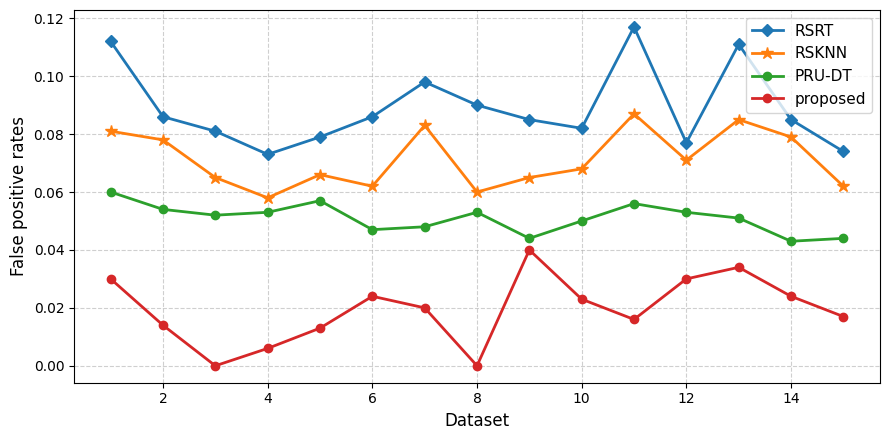

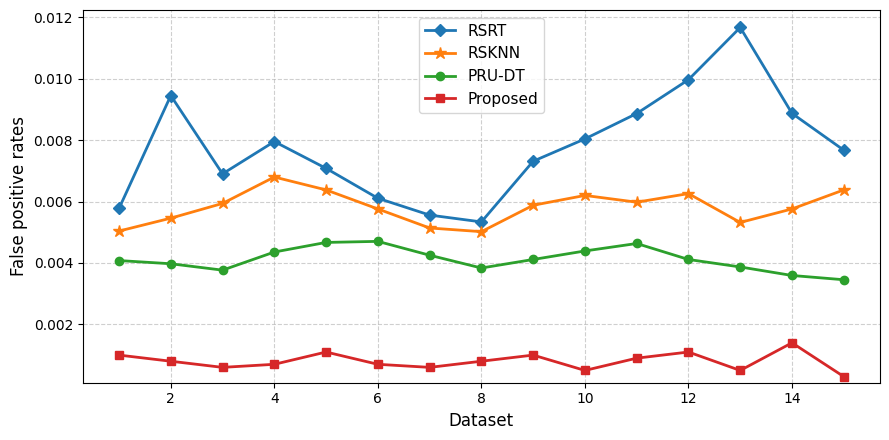

In [21]:
# Plot false positive rates of the proposed approach with other  models
# 15 binary class datasets
import matplotlib.pyplot as plt
import numpy as np

# X-axis (Datasets)
datasets = np.arange(1, 16)

# ================= RSRT =================
rsrt = [
    0.112, 0.086, 0.081, 0.073, 0.079,
    0.086, 0.098, 0.090, 0.085, 0.082,
    0.117, 0.077, 0.111, 0.085, 0.074
]

# ================= RSKNN =================
rsknn = [
    0.081, 0.078, 0.065, 0.058, 0.066,
    0.062, 0.083, 0.060, 0.065, 0.068,
    0.087, 0.071, 0.085, 0.079, 0.062
]

# ================= PRU-DT =================
prudt = [
    0.060, 0.054, 0.052, 0.053, 0.057,
    0.047, 0.048, 0.053, 0.044, 0.050,
    0.056, 0.053, 0.051, 0.043, 0.044
]
# ================= proposed =================
proposed = [
    0.03, 0.014, 0.000, 0.006, 0.013,
    0.024, 0.02, 0.000, 0.040, 0.023,
    0.016, 0.030, 0.034, 0.024, 0.017
]
# Create figure
plt.figure(figsize=(9, 4.5))

# Plot lines
plt.plot(datasets, rsrt, marker='D', linewidth=2, label='RSRT')
plt.plot(datasets, rsknn, marker='*', linewidth=2, markersize=9, label='RSKNN')
plt.plot(datasets, prudt, marker='o', linewidth=2, label='PRU-DT')
plt.plot(datasets, proposed, marker='o', linewidth=2, label='proposed')

# Labels
plt.xlabel('Dataset', fontsize=12)
plt.ylabel('False positive rates', fontsize=12)   # change label if needed (e.g. Error, Std, Time)

# Grid
plt.grid(True, linestyle='--', alpha=0.6)

# Legend
plt.legend(fontsize=11)

# Layout
plt.tight_layout()
plt.savefig("BINARY FPR.svg", dpi=500, bbox_inches="tight")
# Show plot
plt.show()

# **************************************************************************

# 15 multi class datasets
import matplotlib.pyplot as plt
import numpy as np

# X-axis (Datasets)
datasets = np.arange(1, 16)

# ================= RSRT =================
rsrt = [
    0.0057750000, 0.0094518224, 0.0069035981, 0.0079553738, 0.0070821495,
    0.0061089252, 0.0055607477, 0.0053375234, 0.0073142991, 0.0080410748,
    0.0088678972, 0.0099696729, 0.0116714486, 0.0088732243, 0.0076750000
]

# ================= RSKNN =================
rsknn = [
    0.0050400000, 0.0054600000, 0.0059400000, 0.0068000000, 0.0063800000,
    0.0057600000, 0.0051400000, 0.0050200000, 0.0058800000, 0.0062000000,
    0.0059800000, 0.0062600000, 0.0053200000, 0.0057600000, 0.0063800000
]

# ================= PRU-DT =================
prudt = [
    0.0040791667, 0.0039750000, 0.0037666667, 0.0043569444, 0.0046694444,
    0.0047041667, 0.0042527778, 0.0038361111, 0.0041138889, 0.0043916667,
    0.0046347222, 0.0041138889, 0.0038708333, 0.0035930556, 0.0034541667
]

# ================= Proposed =================
proposed = [
    0.0010, 0.0008, 0.0006, 0.0007, 0.0011,
    0.0007, 0.0006, 0.0008, 0.0010, 0.0005,
    0.0009, 0.0011, 0.0005, 0.00140, 0.0003
]

# Create figure
plt.figure(figsize=(9, 4.5))

# Plot lines
plt.plot(datasets, rsrt, marker='D', linewidth=2, label='RSRT')
plt.plot(datasets, rsknn, marker='*', linewidth=2, markersize=9, label='RSKNN')
plt.plot(datasets, prudt, marker='o', linewidth=2, label='PRU-DT')
plt.plot(datasets, proposed, marker='s', linewidth=2, label='Proposed')

# Labels
plt.xlabel('Dataset', fontsize=12)
plt.ylabel('False positive rates', fontsize=12)

# Grid
plt.grid(True, linestyle='--', alpha=0.6)

# Legend
plt.legend(fontsize=11)

# Layout
plt.tight_layout()
plt.ylim(bottom=0.0001)
plt.savefig("MULTI FPR.svg", dpi=500, bbox_inches="tight")
# Show plot
plt.show()

Code to show the confusion matrix for multiclass task (see figures 6/7/9), where we provided the Normalized Confusion Matrix (%)

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# PLOTS

# Plot 1: Regular Confusion Matrix
plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=np.sort(np.unique(y_test)),
            yticklabels=np.sort(np.unique(y_test)),
            cbar_kws={'label': 'Count'})

plt.title('Confusion Matrix - Bagging KNN (Counts)', fontsize=16)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot 2: Normalized Confusion Matrix (%)
plt.figure(figsize=(14, 12))
sns.heatmap(cm_normalized, annot=True, fmt='.1f', cmap='Blues',
            xticklabels=np.sort(np.unique(y_test)),
            yticklabels=np.sort(np.unique(y_test)),
            cbar_kws={'label': 'Percentage (%)'})

plt.title('Normalized Confusion Matrix - Bagging KNN (%)', fontsize=16)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("confusion_matrix_bknn_nca_37classes with SMOTE.svg", dpi=600, bbox_inches='tight')
plt.show()

In this code or experiment,  we aim to calculate the Inference/Sample (ms), Model Size (MB), and RAM at Inference (MB) to study the model LightWitness using different libraries (see TABLE VI), some results provided during discussion

In [ ]:
import time
import pickle
import os
import numpy as np
import tracemalloc
from sklearn.neighbors import NeighborhoodComponentsAnalysis
from sklearn.ensemble import BaggingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score
import warnings
warnings.filterwarnings('ignore')


# STEP 1 — Train NCA ONCE — measure separately

nca = NeighborhoodComponentsAnalysis(
    n_components=7,
    random_state=42,
    max_iter=30,
    tol=1e-03,
)

knn = KNeighborsClassifier(
    metric='manhattan',
    n_neighbors=1,
    algorithm='kd_tree'
)

# Train NCA only once
nca_start = time.perf_counter()
X_train_nca = nca.fit_transform(X_train_selected, y_train)
nca_time = time.perf_counter() - nca_start

# Transform test set once
if hasattr(X_test_selected, 'values'):
    X_test_np = X_test_selected.values
else:
    X_test_np = np.array(X_test_selected)

X_test_nca = nca.transform(X_test_np)

print("=" * 60)
print(f"NCA Training Time : {nca_time:.4f} sec")
print(f"NCA components    : {nca.n_components}")
print("=" * 60)


# STEP 2 — Find Best n_estimators
# Only BKNN changes — NCA stays fixed

print("\nSearching best n_estimators...")
print("-" * 70)
print(f"{'n_est':>6} | {'Accuracy':>10} | "
      f"{'F1':>10} | {'Infer(ms)':>12} | "
      f"{'BKNN Train(s)':>14}")
print("-" * 70)

best_config = {
    'n_est': None,
    'acc': 0,
    'f1': 0,
    'infer_ms': None,
    'bknn_time': None
}

for n_est in [5, 10, 15, 20]:

    # Train BKNN only — NCA already trained
    bagging_knn = BaggingClassifier(
        estimator=knn,
        n_estimators=n_est,
        max_samples=1.0,
        bootstrap=True,
        n_jobs=-1,
        random_state=42
    )

    bknn_start = time.perf_counter()
    bagging_knn.fit(X_train_nca, y_train)  # use pre-trained NCA output
    bknn_time = time.perf_counter() - bknn_start

    # Accuracy on pre-transformed test set
    y_pred = bagging_knn.predict(X_test_nca)
    acc = accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred,
                   average='binary',
                   zero_division=0)

    # Inference time — NCA transform + BKNN predict together
    # This is what runs at deployment
    batch_times = []
    for _ in range(50):
        start = time.perf_counter()
        X_t = nca.transform(X_test_np)   # NCA at inference
        p   = bagging_knn.predict(X_t)    # BKNN at inference
        end = time.perf_counter()
        batch_times.append(
            (end - start) * 1000 / len(X_test_np)
        )

    mean_ms = np.mean(batch_times)
    std_ms  = np.std(batch_times)

    print(f"{n_est:>6} | "
          f"{acc*100:>9.2f}% | "
          f"{f1*100:>9.2f}% | "
          f"{mean_ms:>9.4f} ms | "
          f"{bknn_time:>13.4f}s")

    # Track best result
    # Priority: accuracy first, then inference speed
    if acc > best_config['acc']:
        best_config.update({
            'n_est':      n_est,
            'acc':        acc,
            'f1':         f1,
            'infer_ms':   mean_ms,
            'std_ms':     std_ms,
            'bknn_time':  bknn_time,
            'model':      bagging_knn
        })

print("-" * 70)
print(f"\nBest n_estimators = {best_config['n_est']}"
      f" (Acc={best_config['acc']*100:.2f}%,"
      f" Infer={best_config['infer_ms']:.4f}ms)")


# STEP 3 — Final Measurements with Best Configuration

print("\n" + "=" * 60)
print("STEP 3: FINAL MEASUREMENTS")
print("=" * 60)

# Use the best model found
bagging_knn_final = BaggingClassifier(
    estimator=knn,
    n_estimators=5,
    max_samples=1.0,
    bootstrap=True,
    n_jobs=-1,
    random_state=42
)

# Train NCA + BKNN — measure total training time
total_train_start = time.perf_counter()

# NCA (already trained above )
X_train_nca_final = nca.fit_transform(X_train_selected, y_train)

# BKNN
bagging_knn_final.fit(X_train_nca_final, y_train)

total_train_time = time.perf_counter() - total_train_start


# FINAL INFERENCE TIME — 100 runs for stability
# Measures NCA transform + BKNN predict together

X_test_nca_final = nca.transform(X_test_np)

batch_times_final = []
for _ in range(100):
    start = time.perf_counter()
    X_t = nca.transform(X_test_np)         # NCA at inference
    p   = bagging_knn_final.predict(X_t)    # BKNN at inference
    end = time.perf_counter()
    batch_times_final.append(
        (end - start) * 1000 / len(X_test_np)
    )

mean_ms_final = np.mean(batch_times_final)
std_ms_final  = np.std(batch_times_final)


# MODEL SIZE — Pickle file size, for NCA matrix + BKNN ensemble

with open('nca_final.pkl', 'wb') as f:
    pickle.dump(nca, f)
with open('bknn_final.pkl', 'wb') as f:
    pickle.dump(bagging_knn_final, f)

nca_mb   = os.path.getsize('nca_final.pkl')  / (1024*1024)
bknn_mb  = os.path.getsize('bknn_final.pkl') / (1024*1024)
total_mb = nca_mb + bknn_mb

os.remove('nca_final.pkl')
os.remove('bknn_final.pkl')


# RAM AT INFERENCE — using tracemalloc

tracemalloc.stop()
tracemalloc.clear_traces()
tracemalloc.start()

_ = nca.transform(X_test_np)
_ = bagging_knn_final.predict(_)

current, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()
peak_mb = peak / (1024*1024)


# FINAL PERFORMANCE

y_pred_final = bagging_knn_final.predict(X_test_nca_final)
acc_final = accuracy_score(y_test, y_pred_final)
f1_final  = f1_score(y_test, y_pred_final,
                     average='binary',
                     zero_division=0)


# FINAL SUMMARY

print("\n" + "=" * 55)
print("FINAL SUMMARY — COPY INTO PAPER TABLE VI")
print("=" * 55)
print(f"{'Metric':<30} {'Value'}")
print("-" * 55)
print(f"{'NCA Training Time':<30} {nca_time:.4f} sec")
print(f"{'BKNN Training Time':<30} "
      f"{best_config['bknn_time']:.4f} sec")
print(f"{'Total Training Time':<30} {total_train_time:.4f} sec")
print(f"{'Inference/Sample (NCA+BKNN)':<30} "
      f"{mean_ms_final:.4f} +/- {std_ms_final:.4f} ms")
print(f"{'NCA Model Size':<30} {nca_mb:.4f} MB")
print(f"{'BKNN Model Size':<30} {bknn_mb:.4f} MB")
print(f"{'Total Model Size':<30} {total_mb:.4f} MB")
print(f"{'RAM at Inference':<30} {peak_mb:.4f} MB")
print(f"{'Accuracy':<30} {acc_final*100:.2f}%")
print(f"{'F1-Score (weighted)':<30} {f1_final*100:.2f}%")
print(f"{'Best n_estimators':<30} {best_config['n_est']}")
print("=" * 55)
print("NOTE: Inference = NCA transform + BKNN predict")
print("NOTE: RFECV excluded — not applied at inference")
print("NOTE: Training is offline — one-time cost")
print("=" * 55)

In this code, we try to show the ditribution of class events after applyig the NCA technique, where the events effectively seperated, represeting how NCA can help KNN classifier to desciminate between attacks classes. in this code we can show for all 37 events and we can also show for 7 classes (see figure 8)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.neighbors import NeighborhoodComponentsAnalysis
import matplotlib.cm as cm

# ─── Extract target class 'marker' (values 1 to 37) ──────────────────────────
y_train = df_train['marker'].values
y_test  = df_test['marker'].values

# ─── Apply NCA ────────────────────────────────────────────────────────────────
nca = NeighborhoodComponentsAnalysis(n_components=2, random_state=42, max_iter=1000, tol=1e-10)
X_train_nca = nca.fit_transform(X_train_selected, y_train)
X_test_nca  = nca.transform(X_test_selected)

y_train_arr = np.array(y_train)

# ─── Replace these with your actual 37 event names ───────────────────────────
event_names = {
    1:  'Event_1',
    2:  'Event_2',
    3:  'Event_3',
    4:  'Event_4',
    5:  'Event_5',
    6:  'Event_6',
    7:  'Event_7',
    8:  'Event_8',
    9:  'Event_9',
    10: 'Event_10',
    11: 'Event_11',
    12: 'Event_12',
    13: 'Event_13',
    14: 'Event_14',
    15: 'Event_15',
    16: 'Event_16',
    17: 'Event_17',
    18: 'Event_18',
    19: 'Event_19',
    20: 'Event_20',
    21: 'Event_21',
    22: 'Event_22',
    23: 'Event_23',
    24: 'Event_24',
    25: 'Event_25',
    26: 'Event_26',
    27: 'Event_27',
    28: 'Event_28',
    29: 'Event_29',
    30: 'Event_30',
    31: 'Event_31',
    32: 'Event_32',
    33: 'Event_33',
    34: 'Event_34',
    35: 'Event_35',
    36: 'Event_36',
    37: 'Event_37',
}

# ─── Sanity check ─────────────────────────────────────────────────────────────
print("Class → Event Name → Sample Count:")
for cls, name in event_names.items():
    count = (y_train_arr == cls).sum()
    print(f"  Class {cls:2d} → '{name}' — {count} samples")

# ─── Auto-generate styles ─────────────────────────────────────────────────────
markers_list = ['o', 's', 'D', '^', 'v', 'P', '*']
cmap         = cm.get_cmap('tab20', 37)
colors       = [cmap(i) for i in range(37)]

class_styles = {
    cls: {
        'color':  colors[cls - 1],              # cls 1→index 0, cls 37→index 36
        'marker': markers_list[(cls - 1) % len(markers_list)],
        's':      30,
        'label':  event_names[cls]
    }
    for cls in range(1, 38)
}

# ─── Plot ─────────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(16, 11))
ax  = fig.add_subplot(111, projection='3d')

for cls, style in class_styles.items():
    mask = y_train_arr == cls
    if mask.sum() == 0:
        continue
    ax.scatter(
        X_train_nca[mask, 0],
        X_train_nca[mask, 1],
        np.full(mask.sum(), cls),       # Z = class number (1 to 37)
        c=[style['color']],
        marker=style['marker'],
        s=style['s'],
        alpha=0.7,
        label=style['label'],
        depthshade=True
    )

# ─── Axis labels ──────────────────────────────────────────────────────────────
ax.set_xlabel('Component 1', fontsize=12, labelpad=10)
ax.set_ylabel('Component 2', fontsize=12, labelpad=10)
ax.set_zlabel('Marker',      fontsize=11, labelpad=10)

# Z ticks show class number + event name
ax.set_zticks(list(range(1, 38)))
ax.set_zticklabels(
    [f"{cls}: {event_names[cls]}" for cls in range(1, 38)],
    fontsize=6
)
ax.set_zlim(0.5, 37.5)

# here is the legend
ax.legend(
    title='Marker',
    title_fontsize=9,
    fontsize=7,
    loc='upper center',
    bbox_to_anchor=(0.5, -0.05),
    ncol=6,
    framealpha=0.9
)

ax.view_init(elev=20, azim=-60)
ax.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.savefig("NCA_Embedding_3D_37classes.svg", dpi=1000, bbox_inches='tight')
plt.show()